## Installation

In [ ]:
!pip install "cellpose<4" --no-deps
!pip install fastremap imagecodecs roifile fill-voids natsort

## Setup

In [2]:
import torch
import numpy as np
from PIL import Image
from cellpose import models, utils

In [4]:
from google.colab import drive
drive.mount('/content/drive')

dir = "/content/drive/MyDrive/BMT_tiles_attention/BMT_tiles_attention/"

Mounted at /content/drive


In [5]:
def nuc_ratios(cells,nuclei):
    ratios = []

    # id == 0 (background, não é célula)
    ids_cells = np.unique(cells)
    if ids_cells[0] == 0:
        ids_cells = ids_cells[1:]
    for i in ids_cells:
        # Célula de id == i
        cell = (cells == i)

        # id == 0 (background, não é núcleo)
        ids_nucleos = np.unique(nuclei[cell])
        if ids_nucleos[0] == 0:
            ids_nucleos = ids_nucleos[1:]

        # Uma célula pode conter mais de um núcleo (consideramos que um núcleo pertence à célula se >50% de sua área está contida nela)
        area_nucleos = 0
        for j in ids_nucleos:
            # Núcleo de id == j
            nuc = (nuclei == j)

            area_tot_nuc = nuc.sum()
            # Núcleo de id == j dentro de 'cell'
            area_ins_nuc = (nuclei[cell] == j).sum()

            if (area_ins_nuc / area_tot_nuc) > 0.5:
                area_nucleos += area_ins_nuc

        area_cell = cell.sum()

        # Ignoramos núcleos com área 0
        if area_nucleos == 0:
            continue

        # Segmentação ruim
        if (area_nucleos / area_cell) >= 0.95:
            continue

        ratios.append(area_nucleos / area_cell)

    return ratios

## Cellpose models

In [6]:
cell_model = models.Cellpose(gpu=True, model_type='cyto3')
nuc_model  = models.Cellpose(gpu=True, model_type='nuclei')

100%|██████████| 25.3M/25.3M [00:01<00:00, 19.5MB/s]
100%|██████████| 3.54k/3.54k [00:00<00:00, 20.8MB/s]
100%|██████████| 25.3M/25.3M [00:01<00:00, 20.8MB/s]
100%|██████████| 3.54k/3.54k [00:00<00:00, 34.2MB/s]


## Ratio calculation

In [7]:
def extract_ratios(idx, cell_model, nuc_model):
    paths = [dir + "NIL", dir + "LSIL", dir + "HSIL"]

    all_ratios = []
    for i in range(1,201):
        pil_img = Image.open(paths[idx] + "/" + f"{i}.png").convert("RGB")      # [H, W, 3]
        img = np.array(pil_img)

        cells,  *_ = cell_model.eval(img, diameter=None, channels=[0, 0])
        nuclei, *_ = nuc_model.eval(img, diameter=None, channels=[0, 0], invert=True)

        ratios = nuc_ratios(cells,nuclei)
        if len(ratios) == 0:
            pil_img.close()
            continue

        all_ratios.append(ratios)
        pil_img.close()

    return all_ratios

In [ ]:
import warnings
# Lista vazia
warnings.filterwarnings('ignore', message='Mean of empty slice')
warnings.filterwarnings('ignore', message='invalid value encountered in scalar divide')
# Cellpose não encontrou objetos
#   -> 'no seeds found in get_masks_torch - no masks found'

nil_ratios = np.concatenate(extract_ratios(0,cell_model,nuc_model))
lsil_ratios = np.concatenate(extract_ratios(1,cell_model,nuc_model))
hsil_ratios = np.concatenate(extract_ratios(2,cell_model,nuc_model))

In [9]:
print(len(nil_ratios))
print(len(lsil_ratios))
print(len(hsil_ratios))

331
93
242


## Data analysis

In [10]:
import pandas as pd

data = {'NIL': nil_ratios, 'LSIL': lsil_ratios, 'HSIL': hsil_ratios}

stats = pd.DataFrame({
    k: {'n': len(v), 'média': v.mean(), 'mediana': np.median(v), 'mín': v.min(), 'máx': v.max()}
    for k, v in data.items()
}).T
stats['n'] = stats['n'].astype(int)
stats.round(3)

,n,média,mediana,mín,máx
NIL,331,0.397,0.291,0.040,0.949
LSIL,93,0.833,0.902,0.092,0.949
HSIL,242,0.804,0.857,0.191,0.949


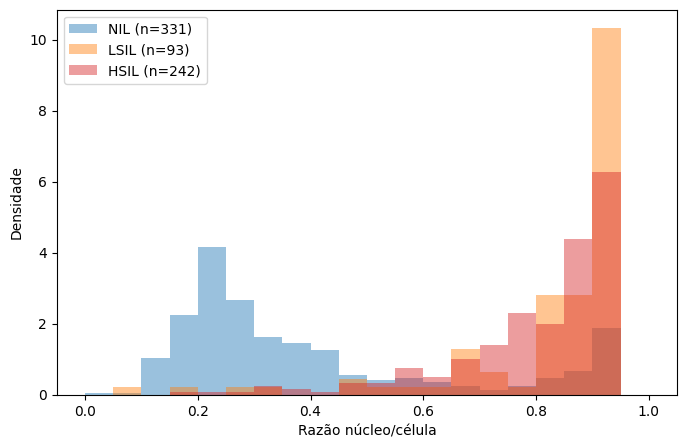

In [11]:
import matplotlib.pyplot as plt

bins = np.linspace(0, 1, 21)
colors = {'NIL': 'tab:blue', 'LSIL': 'tab:orange', 'HSIL': 'tab:red'}

plt.figure(figsize=(8, 5))
for k, v in data.items():
    plt.hist(v, bins=bins, density=True, alpha=0.45, color=colors[k], label=f'{k} (n={len(v)})')
plt.xlabel('Razão núcleo/célula')
plt.ylabel('Densidade')
plt.legend()
plt.show()

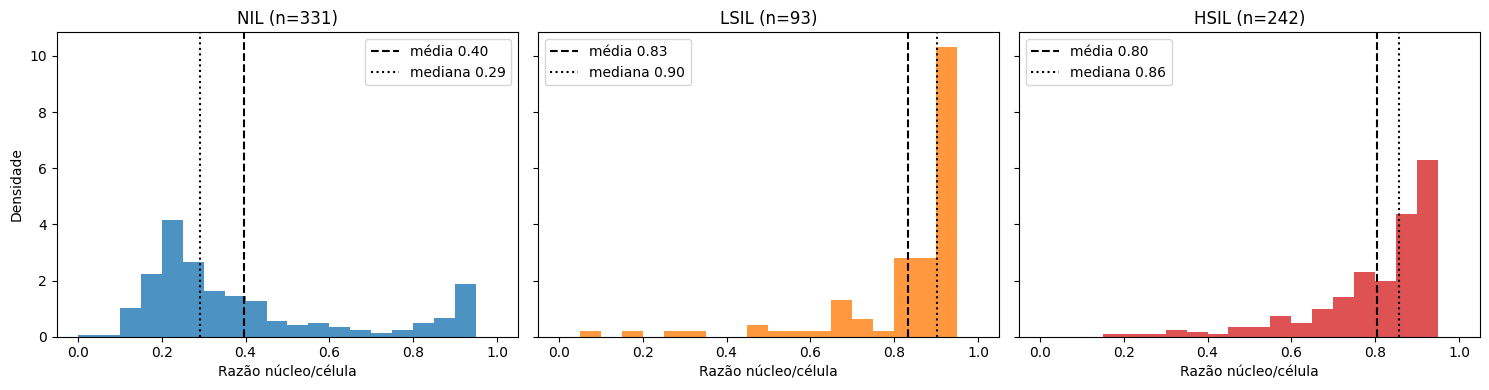

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, (k, v) in zip(axes, data.items()):
    ax.hist(v, bins=bins, density=True, color=colors[k], alpha=0.8)
    ax.axvline(v.mean(), color='k', linestyle='--', label=f'média {v.mean():.2f}')
    ax.axvline(np.median(v), color='k', linestyle=':', label=f'mediana {np.median(v):.2f}')
    ax.set_title(f'{k} (n={len(v)})')
    ax.set_xlabel('Razão núcleo/célula')
    ax.legend()

axes[0].set_ylabel('Densidade')
plt.tight_layout()
plt.show()